# GSA SmartPay purchase-card data

Monthly spend, transactions and card counts by agency, from GSA's SmartPay "Stats Tool" spreadsheet (smartpay.gsa.gov/about/statistics). The notebook downloads the file; nothing is stored in this repo.

This is all purchase-card activity, not only micro-purchases. There is no breakdown by transaction size, merchant, or individual purchase.

In [1]:
import io, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://smartpay.gsa.gov/files/StatsTool_FY26OCT.xlsx"  # check the statistics page for a newer file
req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0 (compatible; data-research)"})
xlsx = urllib.request.urlopen(req).read()

raw = pd.read_excel(io.BytesIO(xlsx), sheet_name="RawData_ByMonth", header=None)
hdr = raw.index[raw.notna().sum(axis=1) >= 8][0]
df = raw.iloc[hdr + 1:].set_axis(raw.iloc[hdr], axis=1).dropna(how="all").reset_index(drop=True)
for col in ["CalendarYear", "CalendarMonth", "Cards", "Spend", "Transactions"]:
    df[col] = pd.to_numeric(df[col])
df["month"] = pd.to_datetime(dict(year=df.CalendarYear, month=df.CalendarMonth, day=1))
print(len(df), "rows,", df.month.min().date(), "to", df.month.max().date())
df.head()

42462 rows, 2008-10-01 to 2026-06-01


0,Group,FiscalYear,CalendarYear,CalendarMonth,Agency,Bank,Cards,Spend,Transactions,ProgramId,Program,Period,AgencyName,OrdinalMonth,Month Name,month
0,SP2,FY09,2008,12,Appalachian Regional Commission,JPMC,441.0,8934.61,242.0,3,Fleet,2008 - December,Small Agencies and Organizations,3,December,2008-12-01
1,SP2,FY09,2009,1,Appalachian Regional Commission,JPMC,441.0,20003.00,55.0,3,Fleet,2009 - January,Small Agencies and Organizations,4,January,2009-01-01
2,SP2,FY09,2009,2,Appalachian Regional Commission,JPMC,1.0,45.36,2.0,3,Fleet,2009 - February,Small Agencies and Organizations,5,February,2009-02-01
3,SP2,FY09,2009,3,Appalachian Regional Commission,JPMC,1.0,26.13,1.0,3,Fleet,2009 - March,Small Agencies and Organizations,6,March,2009-03-01
4,SP2,FY09,2009,4,Appalachian Regional Commission,JPMC,1.0,16.99,1.0,3,Fleet,2009 - April,Small Agencies and Organizations,7,April,2009-04-01


Columns: one row per agency × month × program (Purchase, Travel, Fleet) × bank.

In [2]:
print(df.Program.value_counts(), "\n")
print(sorted(df.AgencyName.unique()))

Program
Purchase        12136
Travel (CBA)    11094
Travel (IBA)    10995
Fleet            8237
Name: count, dtype: int64 

['Agency for International Development', 'Department of Agriculture', 'Department of Commerce', 'Department of Defense', 'Department of Defense - Independent Agencies', 'Department of Education', 'Department of Energy', 'Department of Health and Human Services', 'Department of Homeland Security', 'Department of Housing and Urban Development', 'Department of Interior', 'Department of Justice', 'Department of Labor', 'Department of State', 'Department of Transportation', 'Department of Treasury', 'Department of Veterans Affairs', 'Environmental Protection Agency', 'General Services Administration', 'National Aeronautics and Space Administration (NASA)', 'National Science Foundation', 'Nuclear Regulatory Commission', 'Office of Personnel Management', 'Small Agencies and Organizations', 'Small Business Administration', 'Social Security Administration']


Check: October totals for all programs match GSA's own dashboard tab.

In [3]:
dash = {"FY24": 3014665434.28, "FY25": 3305496742.97, "FY26": 2814090103.33}  # 'GSA SmartPay Dashboard' tab, October
for fy, v in dash.items():
    s = df[(df.FiscalYear == fy) & (df.CalendarMonth == 10)].Spend.sum()
    assert abs(s - v) < 0.01, (fy, s, v)
print("matches")

matches


## Purchase cards, all agencies

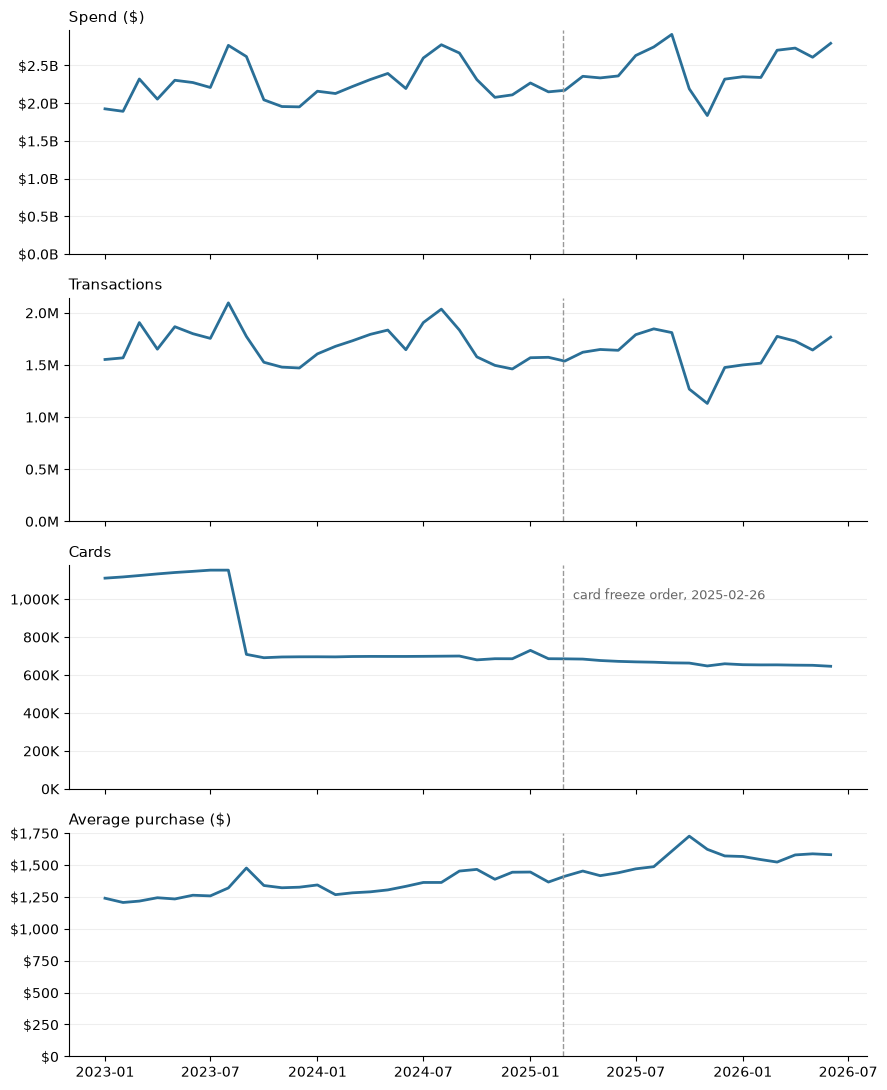

In [4]:
p = df[df.Program == "Purchase"]
nat = p.groupby("month")[["Spend", "Transactions", "Cards"]].sum()
nat["avg_purchase"] = nat.Spend / nat.Transactions
recent = nat[nat.index >= "2023-01-01"]

from matplotlib.ticker import FuncFormatter
fmt = {"Spend": FuncFormatter(lambda v, _: f"${v/1e9:.1f}B"), "Transactions": FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"),
       "Cards": FuncFormatter(lambda v, _: f"{v/1e3:,.0f}K"), "avg_purchase": FuncFormatter(lambda v, _: f"${v:,.0f}")}
fig, axes = plt.subplots(4, 1, figsize=(9, 11), sharex=True)
for ax, col, label in zip(axes, ["Spend", "Transactions", "Cards", "avg_purchase"],
                          ["Spend ($)", "Transactions", "Cards", "Average purchase ($)"]):
    ax.plot(recent.index, recent[col], lw=2, color="#2a6f97")
    ax.yaxis.set_major_formatter(fmt[col])
    ax.set_ylim(bottom=0)
    ax.set_title(label, loc="left", fontsize=11)
    ax.axvline(pd.Timestamp("2025-02-26"), color="#999", lw=1, ls="--")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#eee")
axes[2].text(pd.Timestamp("2025-03-15"), 1.0e6, "card freeze order, 2025-02-26", fontsize=9, color="#666")
plt.tight_layout()

Year-over-year change, same calendar month.

In [5]:
yoy = (nat / nat.shift(12) - 1).mul(100).round(1)
out = pd.DataFrame({"spend_$M": (nat.Spend / 1e6).round(0), "spend_yoy_%": yoy.Spend,
                    "transactions_K": (nat.Transactions / 1e3).round(0), "txn_yoy_%": yoy.Transactions,
                    "cards_K": (nat.Cards / 1e3).round(1), "avg_purchase_$": nat.avg_purchase.round(0)})
out[out.index >= "2024-07-01"]

,spend_$M,spend_yoy_%,transactions_K,txn_yoy_%,cards_K,avg_purchase_$
month,,,,,,
2024-07-01,2599.0,17.7,1907.0,8.6,698.7,1363.0
2024-08-01,2775.0,0.3,2036.0,-2.9,699.4,1363.0
2024-09-01,2665.0,1.8,1835.0,3.5,700.3,1452.0
2024-10-01,2312.0,13.1,1578.0,3.4,680.0,1465.0
2024-11-01,2077.0,6.2,1497.0,1.1,686.2,1388.0
2024-12-01,2110.0,8.2,1462.0,-0.6,686.0,1443.0
2025-01-01,2268.0,5.1,1570.0,-2.3,730.1,1445.0
2025-02-01,2150.0,1.0,1574.0,-6.3,686.2,1366.0
2025-03-01,2170.0,-2.3,1538.0,-11.2,685.5,1411.0


## By agency: March–August 2025 vs. March–August 2024

In [6]:
def window(year, months=range(3, 9)):
    w = p[(p.CalendarYear == year) & (p.CalendarMonth.isin(months))]
    return w.groupby("AgencyName")[["Spend", "Transactions"]].sum()

a, b = window(2024), window(2025)
t = pd.DataFrame({"txn_2024": a.Transactions, "txn_2025": b.Transactions,
                  "spend_2024_$M": (a.Spend / 1e6).round(1), "spend_2025_$M": (b.Spend / 1e6).round(1)})
t["txn_change_%"] = (100 * (t.txn_2025 / t.txn_2024 - 1)).round(1)
t["spend_change_%"] = (100 * (b.Spend / a.Spend - 1)).round(1)
t.sort_values("txn_2024", ascending=False)

,txn_2024,txn_2025,spend_2024_$M,spend_2025_$M,txn_change_%,spend_change_%
AgencyName,,,,,,
Department of Veterans Affairs,3882616.0,3714826.0,8855.0,9754.6,-4.3,10.2
Department of Defense,1769220.0,1492900.0,2674.8,2337.9,-15.6,-12.6
Small Agencies and Organizations,1533086.0,1970495.0,499.2,618.5,28.5,23.9
Department of Justice,986165.0,805490.0,462.5,366.6,-18.3,-20.7
Department of Health and Human Services,616210.0,609428.0,305.3,233.5,-1.1,-23.5
Department of Interior,563942.0,335929.0,315.8,201.6,-40.4,-36.2
Department of Agriculture,491349.0,313931.0,296.0,216.6,-36.1,-26.8
Department of Homeland Security,373609.0,344504.0,346.7,312.5,-7.8,-9.9
Department of Defense - Independent Agencies,207176.0,179430.0,278.1,264.6,-13.4,-4.9


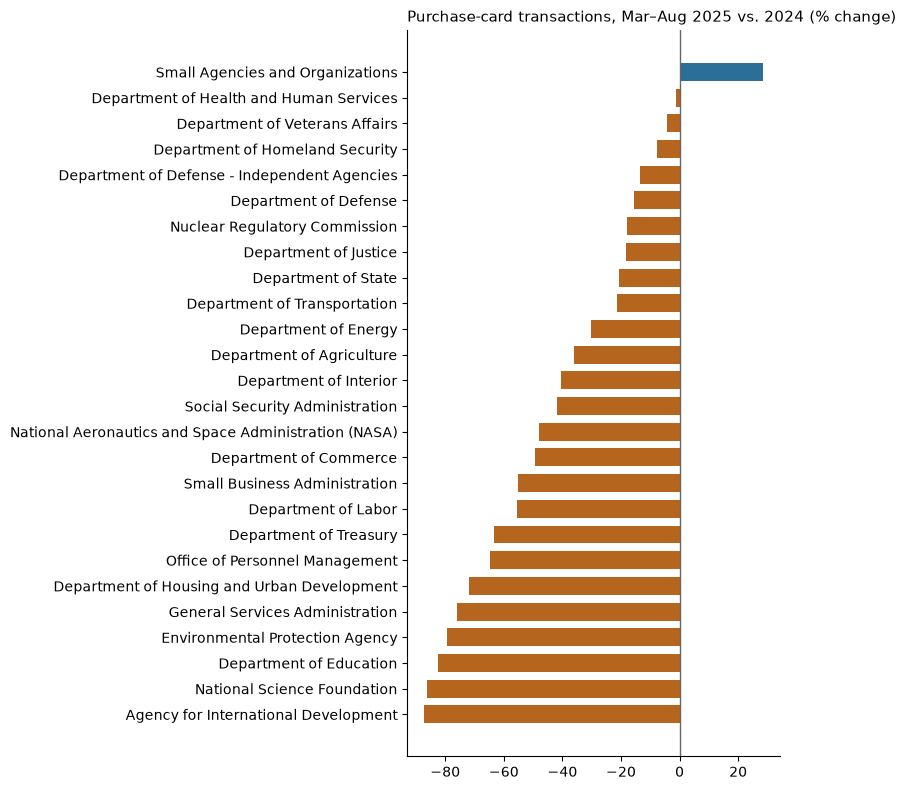

In [7]:
s = t.sort_values("txn_change_%")
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(s.index, s["txn_change_%"], color=["#b5651d" if v < 0 else "#2a6f97" for v in s["txn_change_%"]], height=0.7)
ax.axvline(0, color="#666", lw=1)
ax.set_title("Purchase-card transactions, Mar–Aug 2025 vs. 2024 (% change)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## One agency

In [8]:
def agency(name, program="Purchase", start="2023-01-01"):
    a = df[(df.AgencyName == name) & (df.Program == program)].groupby("month")[["Spend", "Transactions", "Cards"]].sum()
    return a[a.index >= start]

agency("Department of Interior").tail(18)

0,Spend,Transactions,Cards
month,,,
2025-01-01,35012139.78,69731.0,20873.0
2025-02-01,40909721.04,71595.0,20046.0
2025-03-01,8257354.46,13888.0,18969.0
2025-04-01,27293036.27,48600.0,18068.0
2025-05-01,30189799.69,55537.0,17746.0
2025-06-01,34291167.57,61474.0,17242.0
2025-07-01,44674531.50,73758.0,17149.0
2025-08-01,56853207.51,82672.0,17014.0
2025-09-01,49027842.28,67775.0,16892.0


## Caveats

- Card counts have a break in August–September 2023 (about 203,000 fewer under "Small Agencies and Organizations" and 162,000 fewer at HHS, while their spend and transactions don't drop the same way). It looks like a counting change; don't compare card counts across it.
- January 2025's card count (about 730,000) is a one-month spike; December 2024 and February 2025 are both about 686,000. Cards limited to $1 still count as open.
- The government shutdown of Oct 1 – Nov 12, 2025 depresses October–November 2025.
- GSA changed its agency groupings in October 2024 (CFO Act agencies plus "Small Agencies and Organizations"); check that rollup before comparing across that date.
- Drops mix the card freeze with staff cuts and agency closures.
- The spreadsheet's intro sheet says "For Official Use Only," though GSA posts it publicly; this repo links to it rather than copying it.